# Apple Stock Price Prediction – Exploratory Data Analysis

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
%matplotlib inline

## Load Dataset

In [2]:
df = pd.read_csv('Dataset.csv')

---
## 1. Dataset Inspection

### df.head()

In [3]:
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2012-01-03,58.485714,58.928570,58.428570,58.747143,50.765709,75555200
1,2012-01-04,58.571430,59.240002,58.468571,59.062859,51.038536,65005500
2,2012-01-05,59.278572,59.792858,58.952858,59.718571,51.605175,67817400
3,2012-01-06,59.967144,60.392857,59.888573,60.342857,52.144630,79573200
4,2012-01-09,60.785713,61.107143,60.192856,60.247143,52.061932,98506100


### df.tail()

In [4]:
df.tail()

,Date,Open,High,Low,Close,Adj Close,Volume
2006,2019-12-23,280.529999,284.250000,280.369995,284.000000,282.054138,24643000
2007,2019-12-24,284.690002,284.890015,282.920013,284.269989,282.322266,12119700
2008,2019-12-26,284.820007,289.980011,284.700012,289.910004,287.923645,23280300
2009,2019-12-27,291.119995,293.970001,288.119995,289.799988,287.814392,36566500
2010,2019-12-30,289.459991,292.690002,285.220001,291.519989,289.522614,36028600


### df.shape

In [5]:
df.shape

(2011, 7)

### df.columns

In [6]:
df.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume'], dtype='object')

### df.info()

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2011 entries, 0 to 2010
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2011 non-null   object 
 1   Open       2011 non-null   float64
 2   High       2011 non-null   float64
 3   Low        2011 non-null   float64
 4   Close      2011 non-null   float64
 5   Adj Close  2011 non-null   float64
 6   Volume     2011 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 110.1+ KB


### df.describe()

In [8]:
df.describe()

,Open,High,Low,Close,Adj Close,Volume
count,2011.000000,2011.000000,2011.000000,2011.000000,2011.000000,2.011000e+03
mean,126.707469,127.827594,125.580258,126.741235,119.505548,5.949670e+07
std,50.483753,50.926301,50.124940,50.578369,52.438444,4.683856e+07
min,55.424286,57.085712,55.014286,55.790001,48.921928,1.136200e+07
25%,85.882858,86.717858,85.056427,86.202145,75.056679,2.758565e+07
50%,113.050003,114.190002,111.870003,113.050003,105.222908,4.346900e+07
75%,165.190002,167.409996,163.424995,165.245002,160.047111,7.471030e+07
max,291.119995,293.970001,288.119995,291.519989,289.522614,3.765300e+08


---
## 2. Data Quality

### Null Values

In [9]:
df.isnull().sum()

Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

### Duplicate Rows

In [10]:
df.duplicated().sum()

np.int64(0)

### Convert Date & Sort

In [11]:
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)
df.dtypes

Date         datetime64[ns]
Open                float64
High                float64
Low                 float64
Close               float64
Adj Close           float64
Volume                int64
dtype: object

### Duplicate Dates

In [12]:
df['Date'].duplicated().sum()

np.int64(0)

### OHLC Price Consistency

In [13]:
invalid_high = (df['High'] < df['Open']) | (df['High'] < df['Close']) | (df['High'] < df['Low'])
invalid_low = (df['Low'] > df['Open']) | (df['Low'] > df['Close']) | (df['Low'] > df['High'])
print('Rows where High is not the highest:', invalid_high.sum())
print('Rows where Low is not the lowest:', invalid_low.sum())

Rows where High is not the highest: 0
Rows where Low is not the lowest: 0


---
## 3. Price Analysis

### Close & Adj Close Over Time

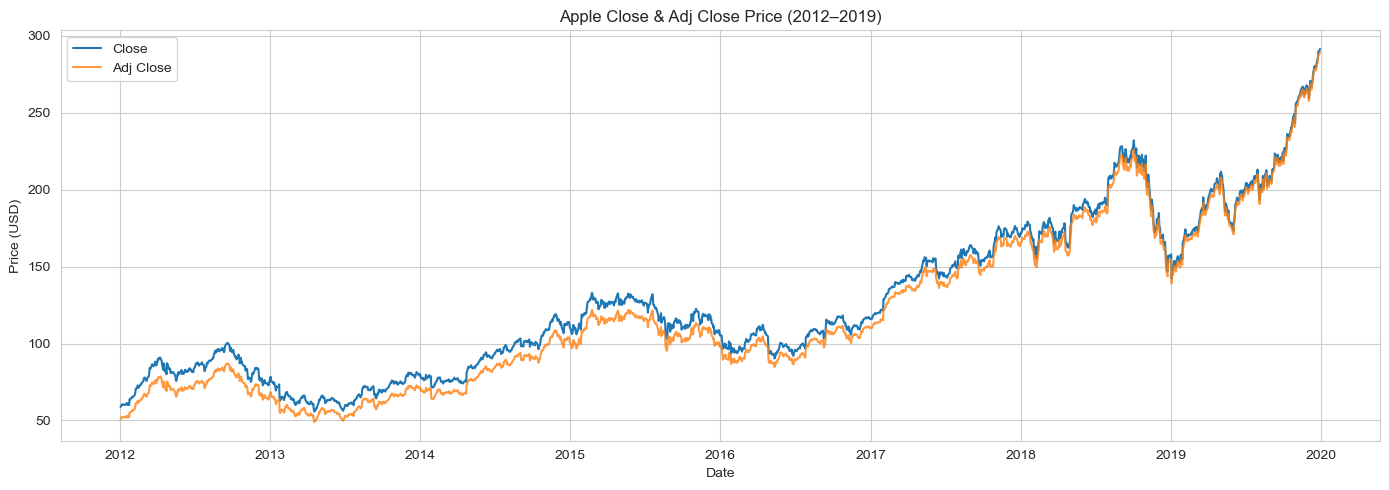

In [14]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df['Date'], df['Close'], label='Close')
ax.plot(df['Date'], df['Adj Close'], label='Adj Close', alpha=0.8)
ax.set_title('Apple Close & Adj Close Price (2012–2019)')
ax.set_xlabel('Date')
ax.set_ylabel('Price (USD)')
ax.legend()
plt.tight_layout()
plt.show()

### Yearly Average Close Price

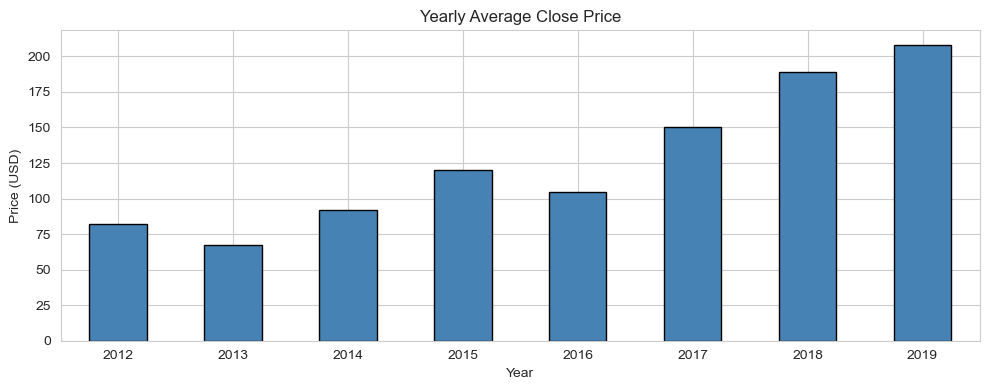

In [15]:
df['Year'] = df['Date'].dt.year
yearly_avg = df.groupby('Year')['Close'].mean()

fig, ax = plt.subplots(figsize=(10, 4))
yearly_avg.plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Yearly Average Close Price')
ax.set_ylabel('Price (USD)')
ax.set_xlabel('Year')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Monthly Average Close Price

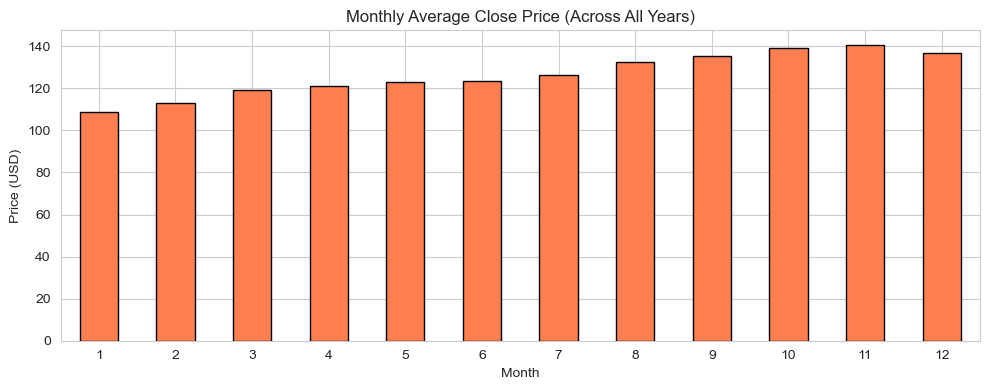

In [16]:
df['Month'] = df['Date'].dt.month
monthly_avg = df.groupby('Month')['Close'].mean()

fig, ax = plt.subplots(figsize=(10, 4))
monthly_avg.plot(kind='bar', ax=ax, color='coral', edgecolor='black')
ax.set_title('Monthly Average Close Price (Across All Years)')
ax.set_ylabel('Price (USD)')
ax.set_xlabel('Month')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Moving Averages (20, 50, 200 Day)

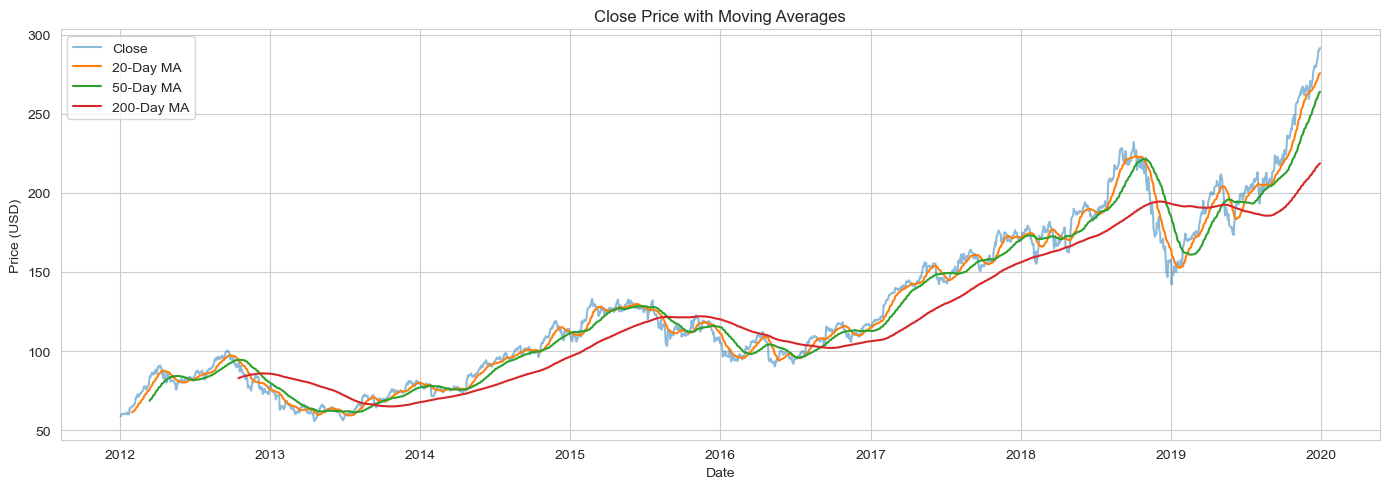

In [17]:
df['MA_20'] = df['Close'].rolling(window=20).mean()
df['MA_50'] = df['Close'].rolling(window=50).mean()
df['MA_200'] = df['Close'].rolling(window=200).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df['Date'], df['Close'], label='Close', alpha=0.5)
ax.plot(df['Date'], df['MA_20'], label='20-Day MA')
ax.plot(df['Date'], df['MA_50'], label='50-Day MA')
ax.plot(df['Date'], df['MA_200'], label='200-Day MA')
ax.set_title('Close Price with Moving Averages')
ax.set_xlabel('Date')
ax.set_ylabel('Price (USD)')
ax.legend()
plt.tight_layout()
plt.show()

---
## 4. Returns and Volatility

### Daily Returns

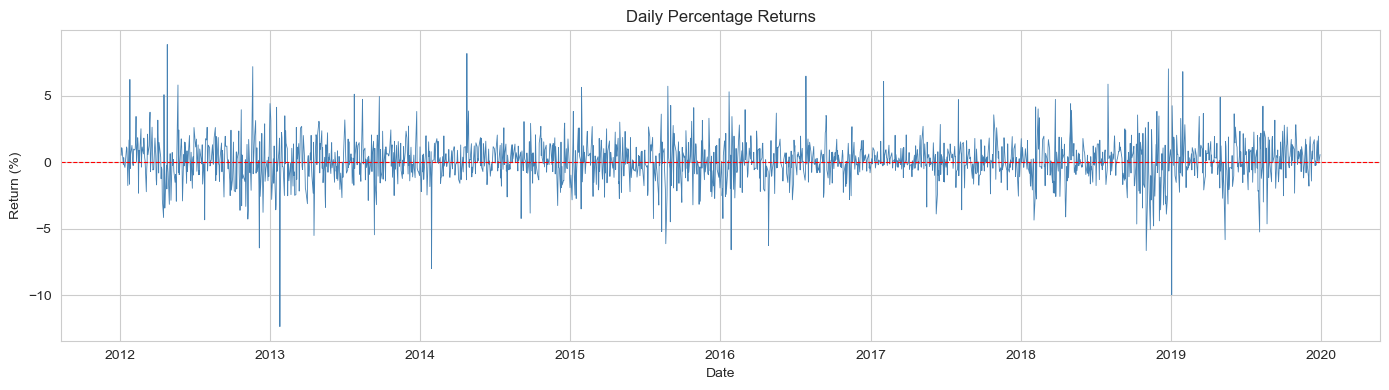

In [18]:
df['Daily_Return'] = df['Close'].pct_change() * 100

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df['Date'], df['Daily_Return'], color='steelblue', linewidth=0.6)
ax.axhline(0, color='red', linestyle='--', linewidth=0.8)
ax.set_title('Daily Percentage Returns')
ax.set_xlabel('Date')
ax.set_ylabel('Return (%)')
plt.tight_layout()
plt.show()

### Daily Returns Distribution

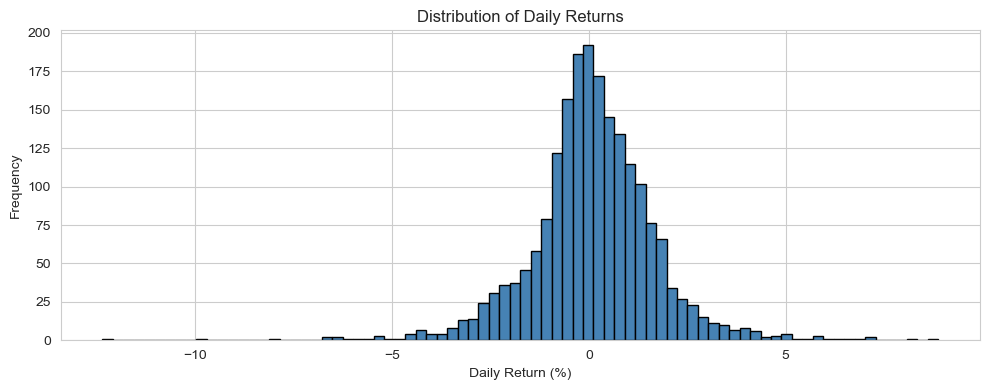

count    2010.000000
mean        0.092755
std         1.612388
min       -12.355795
25%        -0.675187
50%         0.071546
75%         0.957123
max         8.874137
Name: Daily_Return, dtype: float64


In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
df['Daily_Return'].dropna().hist(bins=80, ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Distribution of Daily Returns')
ax.set_xlabel('Daily Return (%)')
ax.set_ylabel('Frequency')
plt.tight_layout()
plt.show()

print(df['Daily_Return'].describe())

### Rolling Volatility (20-Day)

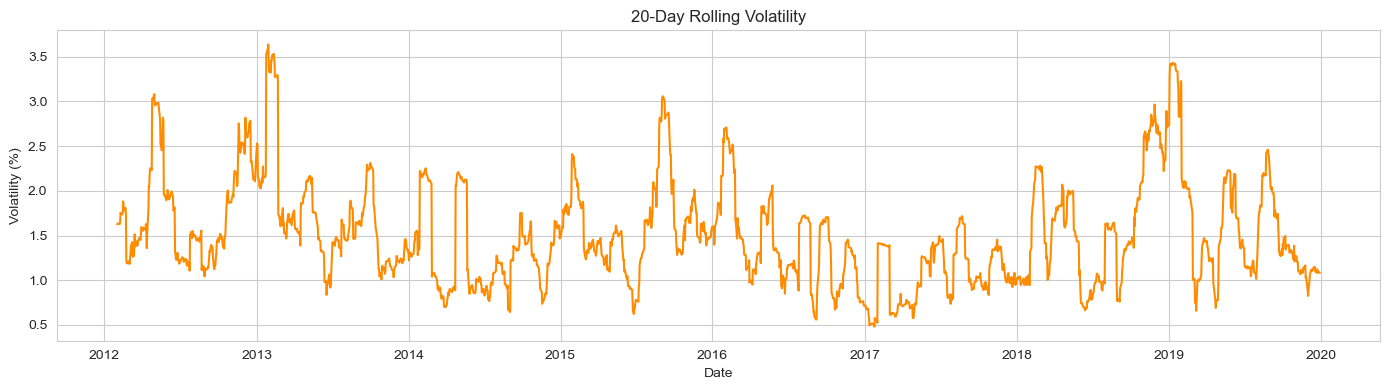

In [20]:
df['Volatility_20'] = df['Daily_Return'].rolling(window=20).std()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df['Date'], df['Volatility_20'], color='darkorange')
ax.set_title('20-Day Rolling Volatility')
ax.set_xlabel('Date')
ax.set_ylabel('Volatility (%)')
plt.tight_layout()
plt.show()

### Potential Outliers in Daily Returns

In [21]:
Q1 = df['Daily_Return'].quantile(0.25)
Q3 = df['Daily_Return'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['Daily_Return'] < lower) | (df['Daily_Return'] > upper)]
print(f'Outlier bounds: [{lower:.2f}%, {upper:.2f}%]')
print(f'Number of potential outliers: {len(outliers)}')
outliers[['Date', 'Close', 'Daily_Return']].head(10)

Outlier bounds: [-3.12%, 3.41%]
Number of potential outliers: 102


,Date,Close,Daily_Return
15,2012-01-25,63.808571,6.243905
26,2012-02-09,70.452858,3.459342
49,2012-03-14,84.225716,3.781026
71,2012-04-16,82.875717,-4.147178
72,2012-04-17,87.099998,5.097128
74,2012-04-19,83.919998,-3.435583
78,2012-04-25,87.142860,8.874137
81,2012-04-30,83.425713,-3.154234
96,2012-05-21,80.182854,5.826009
141,2012-07-25,82.138573,-4.318373


---
## 5. Volume Analysis

### Trading Volume Over Time

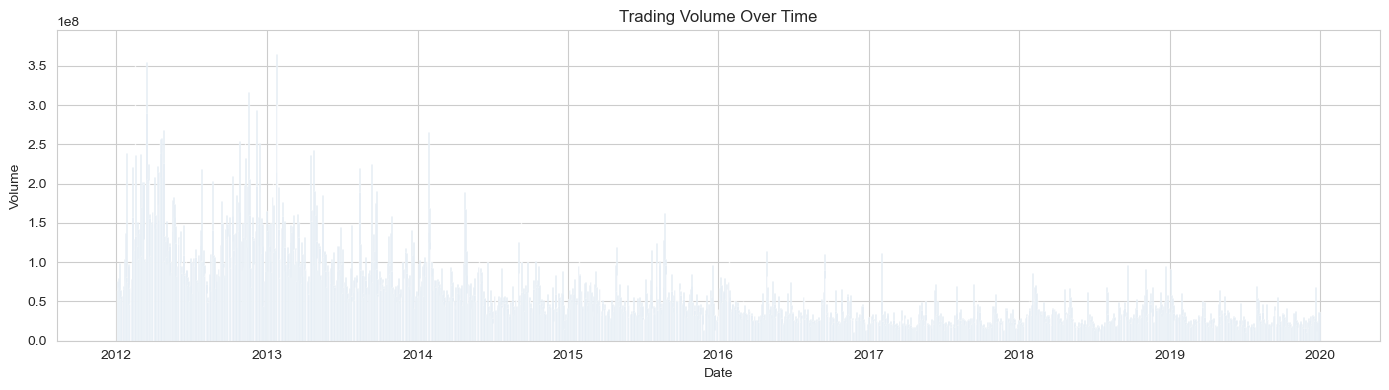

In [22]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(df['Date'], df['Volume'], width=2, color='steelblue', alpha=0.7)
ax.set_title('Trading Volume Over Time')
ax.set_xlabel('Date')
ax.set_ylabel('Volume')
plt.tight_layout()
plt.show()

### Volume vs Close Price

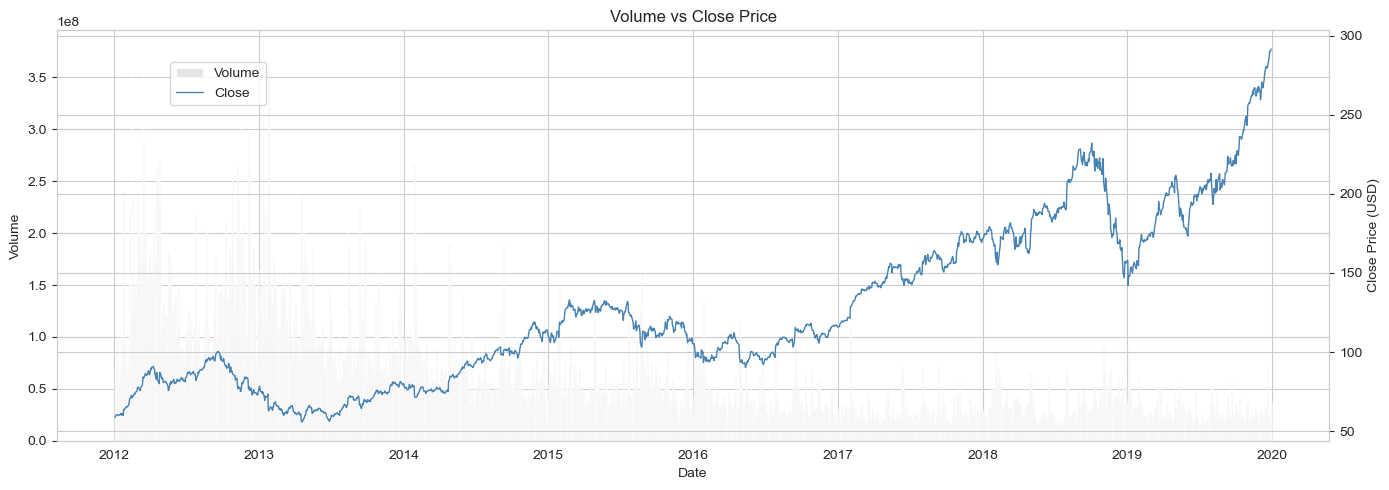

In [23]:
fig, ax1 = plt.subplots(figsize=(14, 5))

ax1.bar(df['Date'], df['Volume'], width=2, color='lightgrey', alpha=0.6, label='Volume')
ax1.set_ylabel('Volume')
ax1.set_xlabel('Date')

ax2 = ax1.twinx()
ax2.plot(df['Date'], df['Close'], color='steelblue', linewidth=1, label='Close')
ax2.set_ylabel('Close Price (USD)')

ax1.set_title('Volume vs Close Price')
fig.legend(loc='upper left', bbox_to_anchor=(0.12, 0.88))
plt.tight_layout()
plt.show()

### Volume vs Daily Returns

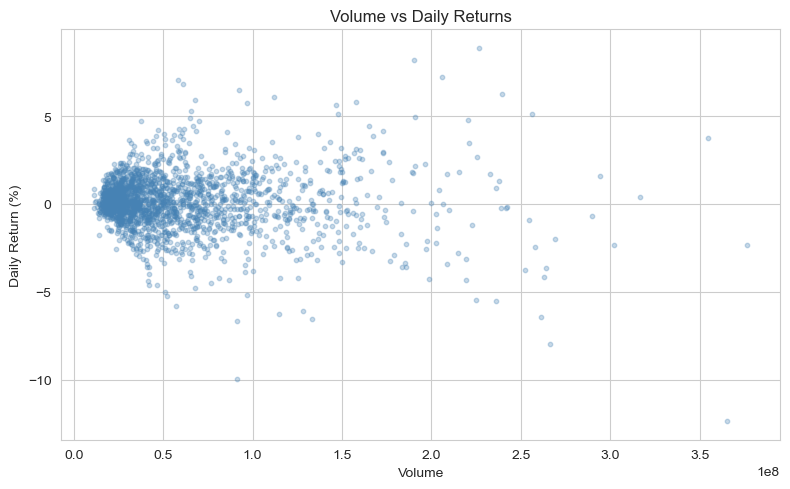

In [24]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df['Volume'], df['Daily_Return'], alpha=0.3, s=10, color='steelblue')
ax.set_title('Volume vs Daily Returns')
ax.set_xlabel('Volume')
ax.set_ylabel('Daily Return (%)')
plt.tight_layout()
plt.show()

---
## 6. Distribution and Correlation

### Distributions

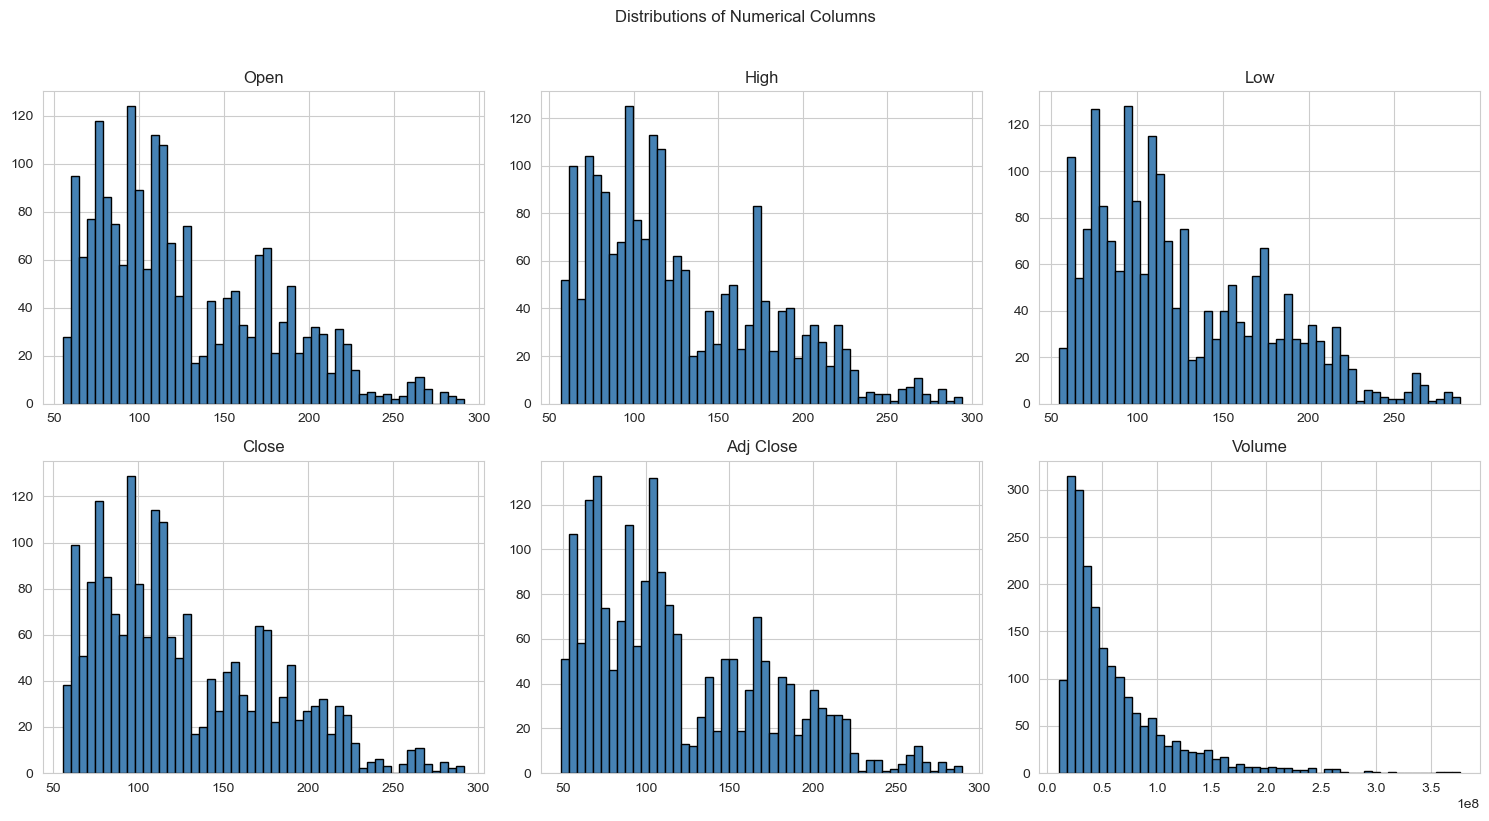

In [25]:
num_cols = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(num_cols):
    ax = axes[i // 3, i % 3]
    df[col].hist(bins=50, ax=ax, color='steelblue', edgecolor='black')
    ax.set_title(col)
plt.suptitle('Distributions of Numerical Columns', y=1.02)
plt.tight_layout()
plt.show()

### Boxplots

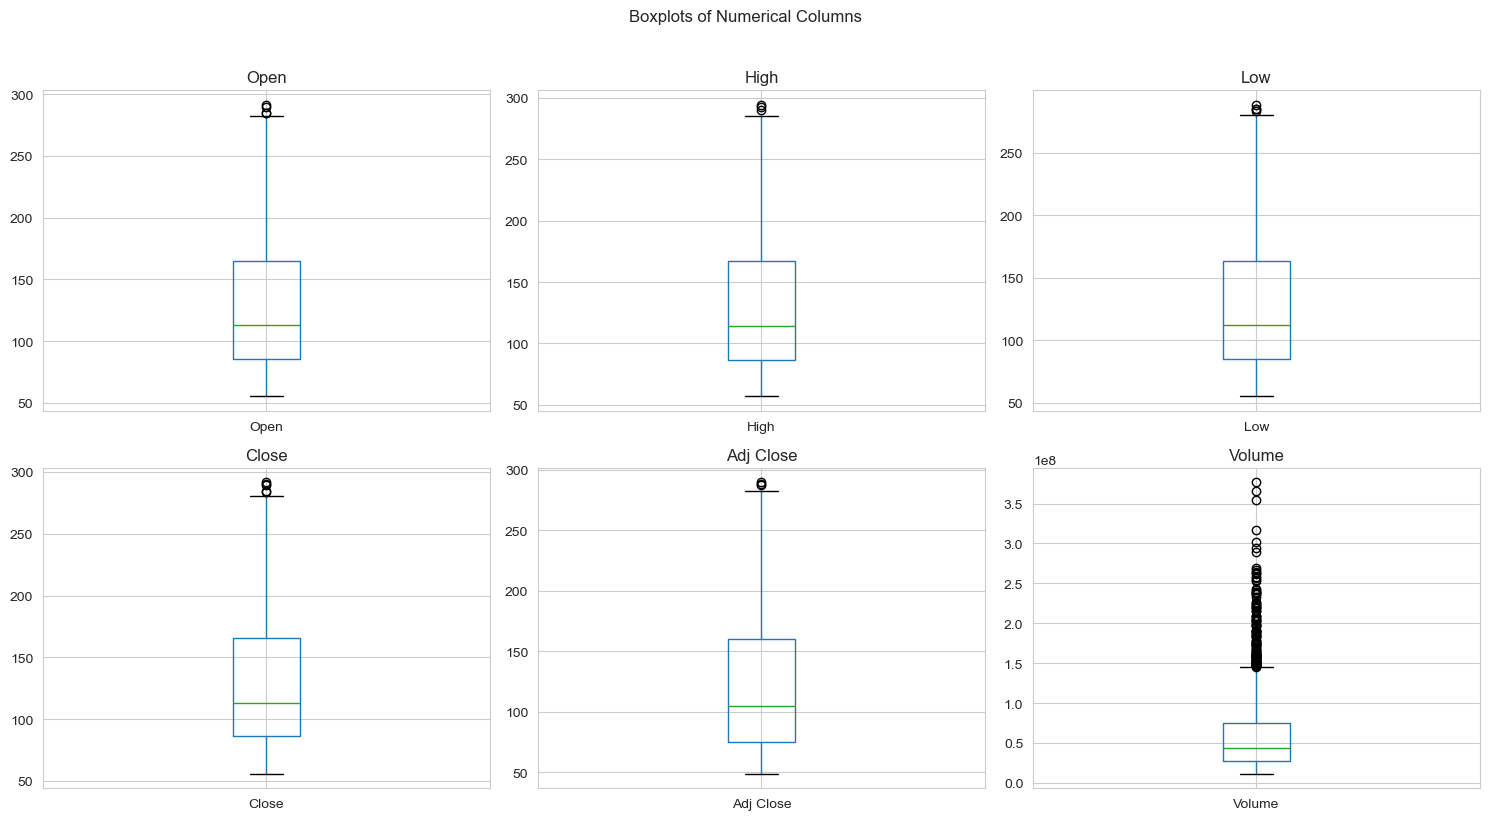

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(num_cols):
    ax = axes[i // 3, i % 3]
    df.boxplot(column=col, ax=ax)
    ax.set_title(col)
plt.suptitle('Boxplots of Numerical Columns', y=1.02)
plt.tight_layout()
plt.show()

### Correlation Heatmap

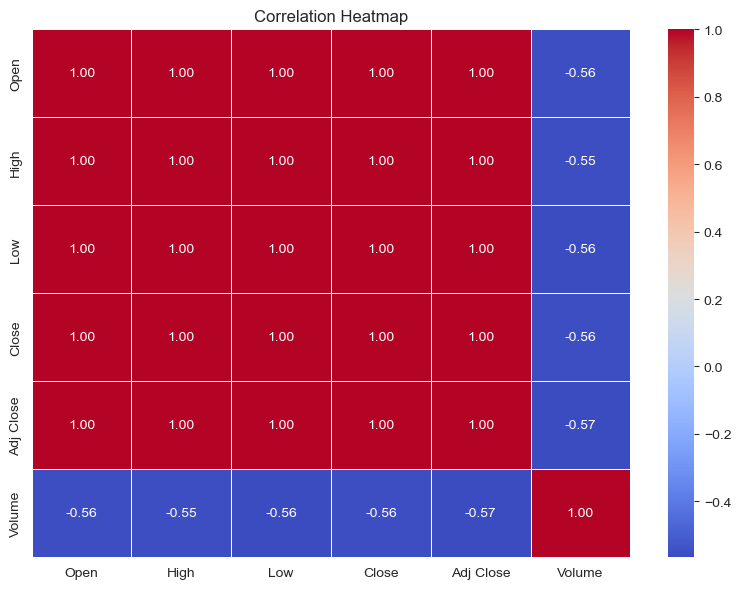

In [27]:
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, ax=ax)
ax.set_title('Correlation Heatmap')
plt.tight_layout()
plt.show()

---
## 7. Time-Series Patterns

### Monthly Seasonality (Boxplot by Month)

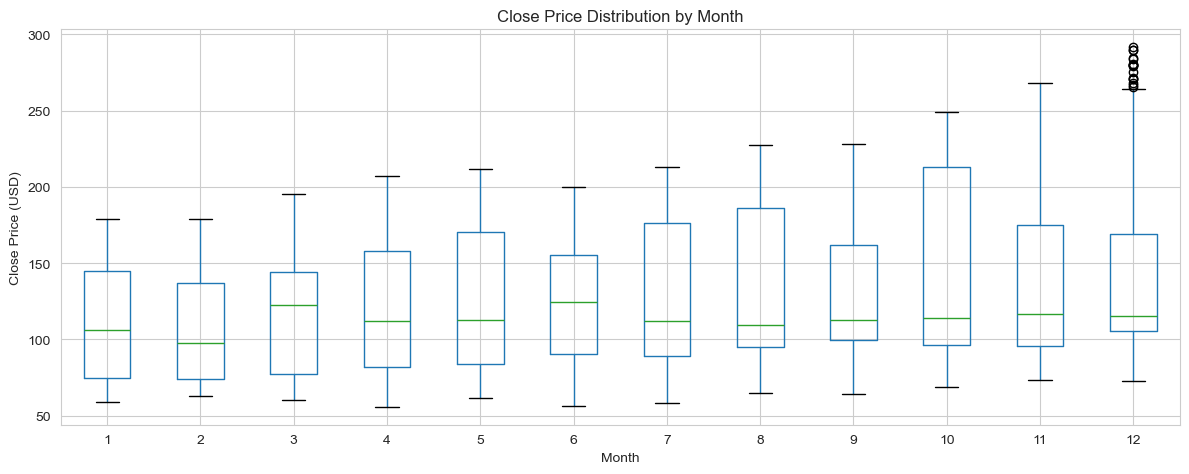

In [28]:
fig, ax = plt.subplots(figsize=(12, 5))
df.boxplot(column='Close', by='Month', ax=ax)
ax.set_title('Close Price Distribution by Month')
ax.set_xlabel('Month')
ax.set_ylabel('Close Price (USD)')
plt.suptitle('')
plt.tight_layout()
plt.show()

### Yearly Seasonality (Boxplot by Year)

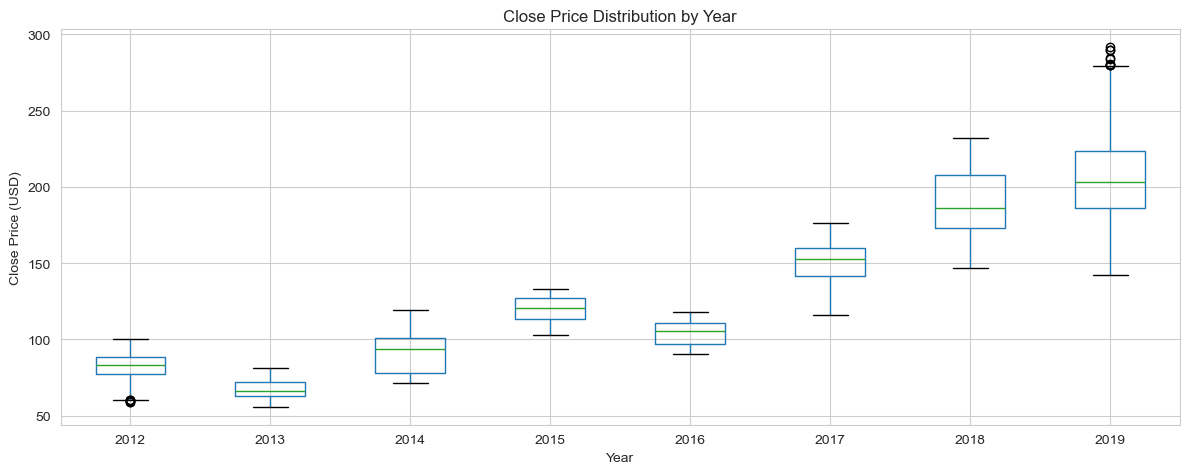

In [29]:
fig, ax = plt.subplots(figsize=(12, 5))
df.boxplot(column='Close', by='Year', ax=ax)
ax.set_title('Close Price Distribution by Year')
ax.set_xlabel('Year')
ax.set_ylabel('Close Price (USD)')
plt.suptitle('')
plt.tight_layout()
plt.show()

### Average Monthly Returns

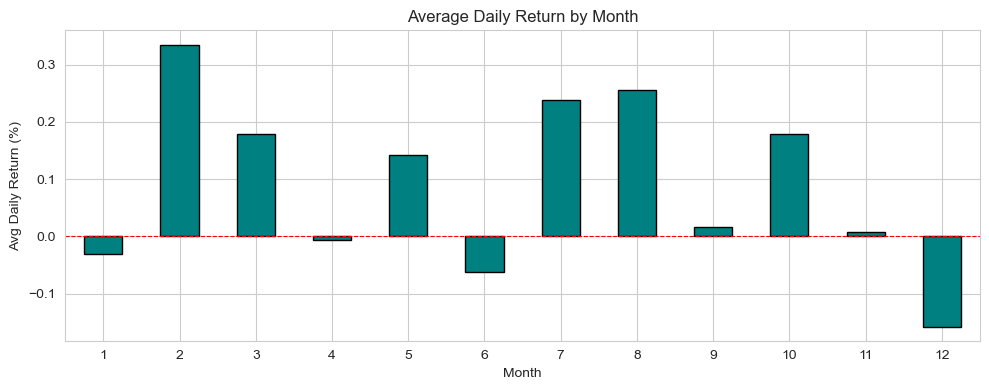

In [30]:
monthly_returns = df.groupby('Month')['Daily_Return'].mean()

fig, ax = plt.subplots(figsize=(10, 4))
monthly_returns.plot(kind='bar', ax=ax, color='teal', edgecolor='black')
ax.axhline(0, color='red', linestyle='--', linewidth=0.8)
ax.set_title('Average Daily Return by Month')
ax.set_xlabel('Month')
ax.set_ylabel('Avg Daily Return (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Autocorrelation (ACF)

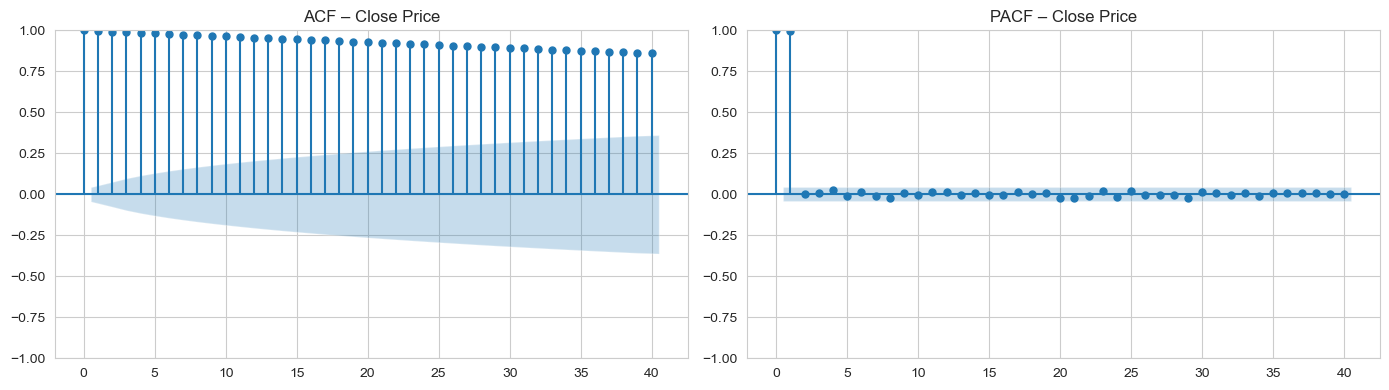

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(df['Close'].dropna(), lags=40, ax=axes[0])
axes[0].set_title('ACF – Close Price')

plot_pacf(df['Close'].dropna(), lags=40, ax=axes[1])
axes[1].set_title('PACF – Close Price')

plt.tight_layout()
plt.show()

### Autocorrelation – Daily Returns

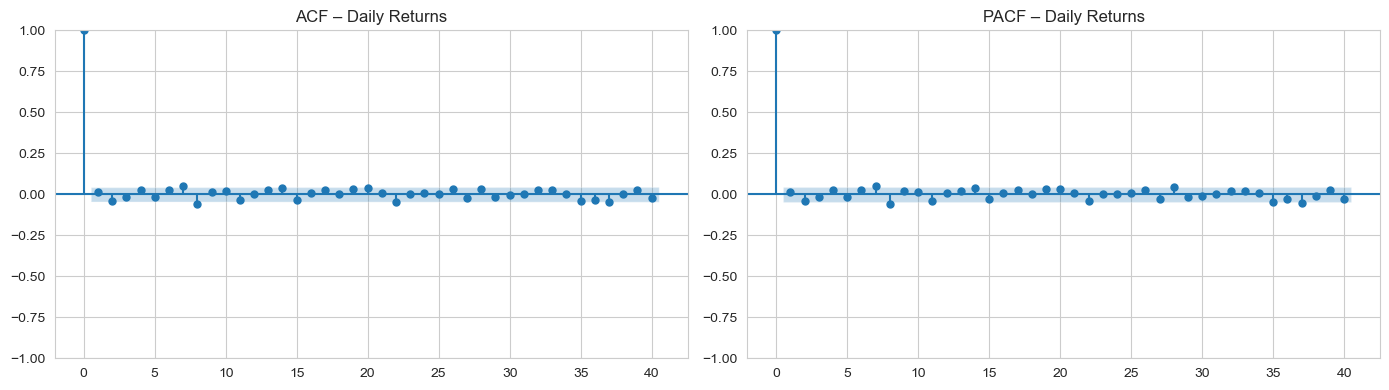

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(df['Daily_Return'].dropna(), lags=40, ax=axes[0])
axes[0].set_title('ACF – Daily Returns')

plot_pacf(df['Daily_Return'].dropna(), lags=40, ax=axes[1])
axes[1].set_title('PACF – Daily Returns')

plt.tight_layout()
plt.show()

---
### Cleanup Helper Columns

In [33]:
df.drop(columns=['Year', 'Month', 'MA_20', 'MA_50', 'MA_200', 'Daily_Return', 'Volatility_20'], inplace=True)
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2012-01-03,58.485714,58.928570,58.428570,58.747143,50.765709,75555200
1,2012-01-04,58.571430,59.240002,58.468571,59.062859,51.038536,65005500
2,2012-01-05,59.278572,59.792858,58.952858,59.718571,51.605175,67817400
3,2012-01-06,59.967144,60.392857,59.888573,60.342857,52.144630,79573200
4,2012-01-09,60.785713,61.107143,60.192856,60.247143,52.061932,98506100


In [34]:
df.tail()

,Date,Open,High,Low,Close,Adj Close,Volume
2006,2019-12-23,280.529999,284.250000,280.369995,284.000000,282.054138,24643000
2007,2019-12-24,284.690002,284.890015,282.920013,284.269989,282.322266,12119700
2008,2019-12-26,284.820007,289.980011,284.700012,289.910004,287.923645,23280300
2009,2019-12-27,291.119995,293.970001,288.119995,289.799988,287.814392,36566500
2010,2019-12-30,289.459991,292.690002,285.220001,291.519989,289.522614,36028600


---
# MODEL BUILDING (rebuilt)

**Plan**
1. Prepare the series (date index, log transform)
2. Check stationarity and pick `d`
3. Read ACF/PACF of the *stationary* series to get candidate `p`, `q`
4. Chronological train/test split (no shuffling, no peeking)
5. Pick the order on the **training set only** (AIC) and check residuals
6. Evaluate on the **test set** with a naive baseline, using walk-forward one-step forecasts
7. Refit on all data and forecast the next 30 trading days with confidence intervals

## 1. Prepare the series

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import itertools

# Date index; model the log of the adjusted close (stabilises variance, differences = log returns)
ts = df[['Date', 'Adj Close']].copy()
ts['Date'] = pd.to_datetime(ts['Date'])
ts = ts.sort_values('Date').drop_duplicates('Date').set_index('Date')['Adj Close']
log_ts = np.log(ts)

print('Observations:', len(ts), '|', ts.index.min().date(), 'to', ts.index.max().date())

## 2. Stationarity and choice of `d`

ARIMA needs a stationary series. We test the log price and its **first difference** (= daily log return).
The earlier notebook differenced at lag 12 (`shift(12)`); that is a 12-day change, not a justified
transformation for daily stock data, so it is replaced by ordinary first differencing.

In [ ]:
def stationarity_report(x, name):
    x = x.dropna()
    adf_stat, adf_p = adfuller(x, autolag='AIC')[:2]
    kpss_stat, kpss_p = kpss(x, regression='c', nlags='auto')[:2]
    print(f'{name:<22} ADF p = {adf_p:.4f} (want < 0.05)   KPSS p = {kpss_p:.4f} (want > 0.05)')

log_ret = log_ts.diff().dropna()
stationarity_report(log_ts, 'Log price')
stationarity_report(log_ret, 'Log return (d = 1)')

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
log_ts.plot(ax=axes[0], title='Log Adj Close (non-stationary: trending)')
log_ret.plot(ax=axes[1], title='First difference of log Adj Close (log return, stationary)', lw=0.6)
plt.tight_layout(); plt.show()

## 3. Seasonality check

Daily equity prices have no reliable calendar seasonality. We look at the seasonal component for a weekly
(5 trading days) and monthly (21 trading days) period instead of assuming 12.

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6))
for ax, p in zip(axes, [5, 21]):
    dec = seasonal_decompose(log_ts, model='additive', period=p)
    dec.seasonal.iloc[:p*6].plot(ax=ax, title=f'Seasonal component, period = {p}')
plt.tight_layout(); plt.show()

# strength of seasonality: 1 - Var(resid) / Var(seasonal + resid)
for p in [5, 21]:
    dec = seasonal_decompose(log_ts, model='additive', period=p)
    r = dec.resid.dropna(); s = dec.seasonal.loc[r.index]
    print(f'period {p:>2}: seasonal strength = {max(0, 1 - r.var()/(r + s).var()):.3f}  (close to 0 = no seasonality)')

## 4. ACF / PACF of the stationary series (log returns)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(log_ret, lags=30, ax=axes[0], title='ACF - log returns')
plot_pacf(log_ret, lags=30, ax=axes[1], title='PACF - log returns', method='ywm')
plt.tight_layout(); plt.show()

## 5. Train / test split

Chronological 80 / 20 split. Everything (order selection, fitting) uses the training part only.

In [ ]:
split = int(len(log_ts) * 0.8)
train_log, test_log = log_ts.iloc[:split], log_ts.iloc[split:]
print(f'Train: {train_log.index.min().date()} -> {train_log.index.max().date()}  ({len(train_log)} rows)')
print(f'Test : {test_log.index.min().date()} -> {test_log.index.max().date()}  ({len(test_log)} rows)')

## 6. Order selection on the training set (AIC), d = 1

In [ ]:
rows = []
for p, q in itertools.product(range(0, 4), range(0, 4)):
    try:
        # trend='t' = drift on the differenced series (stocks tend to drift upward)
        fit = ARIMA(train_log.values, order=(p, 1, q), trend='t').fit()
        rows.append({'p': p, 'd': 1, 'q': q, 'AIC': fit.aic, 'BIC': fit.bic})
    except Exception as e:
        pass

order_table = pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)
display(order_table.head(8))
best_p, _, best_q = order_table.loc[0, ['p', 'd', 'q']].astype(int)
BEST_ORDER = (best_p, 1, best_q)
print('Selected order:', BEST_ORDER)

## 7. Fit the selected model and check residuals

In [ ]:
arima_fit = ARIMA(train_log.values, order=BEST_ORDER, trend='t').fit()
print(arima_fit.summary())

resid = pd.Series(arima_fit.resid).iloc[1:]   # drop first value (diffuse initialisation artefact)
lb = acorr_ljungbox(resid, lags=[10, 20], return_df=True)
print('\nLjung-Box test (p > 0.05 means residuals look like white noise):')
display(lb)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
resid.plot(ax=axes[0], title='Residuals', lw=0.6)
resid.hist(bins=60, ax=axes[1]); axes[1].set_title('Residual distribution')
plot_acf(resid, lags=30, ax=axes[2], title='Residual ACF')
plt.tight_layout(); plt.show()

## 8. Evaluation on the test set

* **Walk-forward one-step-ahead**: each day the model forecasts the next day, then sees the true value.
  Parameters are kept fixed from training (no leakage). This is how the model would be used day to day.
* **Naive baseline**: tomorrow's price = today's price. A model that cannot beat this is not useful.
* **Static multi-step forecast** over the whole test window is shown for completeness, ARIMA reverts to a
  near straight line over long horizons, so it is not a fair accuracy measure.

In [ ]:
def walk_forward(order, train, test, seasonal_order=None):
    # one-step-ahead forecasts on `test`, parameters frozen from `train`
    if seasonal_order is None:
        fit = ARIMA(train.values, order=order, trend='t').fit()
    else:
        fit = SARIMAX(train.values, order=order, seasonal_order=seasonal_order, trend='t').fit(disp=False)
    preds, res = [], fit
    for i in range(len(test)):
        preds.append(float(np.asarray(res.forecast(1))[0]))
        res = res.append(test.values[i:i+1], refit=False)
    return pd.Series(preds, index=test.index), fit

arima_wf, arima_train_fit = walk_forward(BEST_ORDER, train_log, test_log)
naive_wf = log_ts.shift(1).loc[test_log.index]                     # previous day's value

# back to price scale for reporting
actual   = np.exp(test_log)
arima_px = np.exp(arima_wf)
naive_px = np.exp(naive_wf)

In [ ]:
def score(name, y, yhat, prev):
    direction = (np.sign(y.values - prev.values) == np.sign(yhat.values - prev.values)).mean() * 100
    return {'Model': name,
            'MAE ($)': mean_absolute_error(y, yhat),
            'RMSE ($)': np.sqrt(mean_squared_error(y, yhat)),
            'MAPE (%)': mean_absolute_percentage_error(y, yhat) * 100,
            'Directional acc. (%)': direction}

prev_px = np.exp(log_ts.shift(1).loc[test_log.index])
results = pd.DataFrame([
    score('Naive (previous day)', actual, naive_px, prev_px),
    score(f'ARIMA{BEST_ORDER} walk-forward', actual, arima_px, prev_px),
]).set_index('Model').round(3)
display(results)

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
axes[0].plot(np.exp(train_log), label='Train', color='grey', alpha=0.6)
axes[0].plot(actual, label='Test (actual)', color='black')
axes[0].plot(arima_px, label='ARIMA one-step forecast', color='tab:red', alpha=0.8)
axes[0].set_title('Train / test split and one-step-ahead forecast'); axes[0].legend()

last = 60
axes[1].plot(actual.iloc[-last:], label='Actual', color='black')
axes[1].plot(arima_px.iloc[-last:], label='ARIMA', color='tab:red')
axes[1].plot(naive_px.iloc[-last:], label='Naive', color='tab:blue', ls='--')
axes[1].set_title(f'Zoom: last {last} test days'); axes[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
# Static multi-step forecast across the full test window (for illustration only)
static = arima_train_fit.get_forecast(len(test_log))
static_mean = pd.Series(np.exp(static.predicted_mean), index=test_log.index)
ci = np.exp(static.conf_int(alpha=0.05)); ci = pd.DataFrame(ci, index=test_log.index, columns=['lo', 'hi'])

plt.figure(figsize=(14, 5))
plt.plot(np.exp(train_log), color='grey', alpha=0.6, label='Train')
plt.plot(actual, color='black', label='Actual')
plt.plot(static_mean, color='tab:red', label='Multi-step forecast')
plt.fill_between(ci.index, ci['lo'], ci['hi'], color='tab:red', alpha=0.15, label='95% interval')
plt.title('Multi-step forecast from end of training (long horizon = flat line + widening interval)')
plt.legend(); plt.show()

## 9. Does a seasonal model help?

One seasonal candidate with a weekly period (5 trading days) is compared against the plain ARIMA
on the same walk-forward test. Keep it only if it clearly beats the plain model.

In [ ]:
sarima_wf, sarima_fit = walk_forward(BEST_ORDER, train_log, test_log, seasonal_order=(1, 0, 1, 5))
sarima_px = np.exp(sarima_wf)

results = pd.DataFrame([
    score('Naive (previous day)', actual, naive_px, prev_px),
    score(f'ARIMA{BEST_ORDER}', actual, arima_px, prev_px),
    score(f'SARIMA{BEST_ORDER}x(1,0,1,5)', actual, sarima_px, prev_px),
]).set_index('Model').round(3)
display(results)
print('AIC on train  ARIMA :', round(arima_train_fit.aic, 1))
print('AIC on train  SARIMA:', round(sarima_fit.aic, 1))

## 10. Final model: refit on all data and forecast the next 30 trading days

In [ ]:
final_fit = ARIMA(log_ts.values, order=BEST_ORDER, trend='t').fit()
H = 30
fc = final_fit.get_forecast(H)
future_idx = pd.bdate_range(log_ts.index[-1] + pd.Timedelta(days=1), periods=H)   # trading days (weekdays)

forecast_df = pd.DataFrame({
    'Forecast': np.exp(fc.predicted_mean),
    'Lower 95%': np.exp(fc.conf_int(alpha=0.05)[:, 0]),
    'Upper 95%': np.exp(fc.conf_int(alpha=0.05)[:, 1]),
}, index=future_idx).round(2)
display(forecast_df.head(10))

plt.figure(figsize=(14, 5))
plt.plot(ts.iloc[-250:], label='Adj Close (last 250 days)', color='black')
plt.plot(forecast_df['Forecast'], color='tab:red', label='30-day forecast')
plt.fill_between(forecast_df.index, forecast_df['Lower 95%'], forecast_df['Upper 95%'],
                 color='tab:red', alpha=0.15, label='95% interval')
plt.title('Apple Adj Close: 30 trading-day forecast'); plt.legend(); plt.show()

## Conclusions

* Log price is non-stationary and one difference makes it stationary, so `d = 1`.
* Calendar seasonality is negligible, so a plain ARIMA is the right starting point.
* The honest benchmark is the naive (previous-day) forecast, stock prices are close to a random walk, and
  ARIMA gains over naive are expected to be small. Read the table in section 8 and report whatever it shows.
* Long-horizon forecasts are a drift line with a widening interval, not a price prediction.
* Possible next steps: GARCH for volatility, adding Volume/technical indicators in an ARIMAX or LSTM model.